<a href="https://colab.research.google.com/github/tanajue1-design/Intensive-Project/blob/main/PCA_and_development_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

uploaded = files.upload()

uploaded_file = next(iter(uploaded.keys()))

# Extract the CSV if a ZIP file was uploaded
if uploaded_file.lower().endswith(".zip"):
    with zipfile.ZipFile(uploaded_file, "r") as z:
        csv_files = [
            name for name in z.namelist()
            if name.lower().endswith(".csv")
            and "retailmart_transactions_cleaned" in name.lower()
        ]

        if not csv_files:
            raise FileNotFoundError(
                "The ZIP does not contain the cleaned RetailMart CSV."
            )

        csv_name = csv_files[0]

        with z.open(csv_name) as f:
            df = pd.read_csv(f)

elif uploaded_file.lower().endswith(".csv"):
    df = pd.read_csv(uploaded_file)

else:
    raise ValueError("Please upload a CSV or ZIP file.")

print("Dataset loaded successfully.")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print(df.columns.tolist())

df.head()


Saving retailmart_transactions_cleaned-compressed.zip to retailmart_transactions_cleaned-compressed.zip
Dataset loaded successfully.
Rows: 990,078
Columns: 16
['transaction_id', 'customer_id', 'transaction_date', 'product_category', 'product_name', 'quantity', 'unit_price', 'total_amount', 'store_location', 'payment_method', 'customer_age', 'customer_gender', 'loyalty_years', 'num_visits', 'churn', 'transaction_ts']


,transaction_id,customer_id,transaction_date,product_category,product_name,quantity,unit_price,total_amount,store_location,payment_method,customer_age,customer_gender,loyalty_years,num_visits,churn,transaction_ts
0,DUP-00000002,e5fd51bb-e050-43fe-9ea3-cf9973b97dc4,2022-02-09T08:24:36.000Z,Beauty,Makeup Kit,1.0,28.85,28.85,"Las Vegas, NV",Gift Card,19.0,Male,2.0,7.0,No,2022-02-09T08:24:36.000Z
1,DUP-00000003,71f4be1f-6b4d-4c89-a75e-d3d479a2bda4,2025-10-03T16:57:49.000Z,Toys,Board Game,3.0,30.32,90.96,"Austin, TX",Credit Card,42.0,Female,7.0,20.0,No,2025-10-03T16:57:49.000Z
2,DUP-00000004,b638f1ee-1509-41b8-88ce-73eb1bcf2c7a,2025-02-24T21:19:24.000Z,Toys,Building Blocks,1.0,40.18,40.18,"Portland, OR",Mobile Pay,18.0,Non-Binary,5.0,15.0,Yes,2025-02-24T21:19:24.000Z
3,DUP-00000006,458cd193-e95d-4f78-8755-0f0c628dcd24,2023-04-14T11:43:50.000Z,Sports,Tennis Racket,1.0,74.35,74.35,"Las Vegas, NV",Mobile Pay,34.0,Female,5.0,19.0,No,2023-04-14T11:43:50.000Z
4,DUP-00000008,c0b58638-b856-497f-8518-396bf25fd670,2021-02-04T15:25:06.000Z,Sports,Bicycle,2.0,22.59,45.18,"Houston, TX",Cash,24.0,Male,2.0,8.0,Yes,2021-02-04T15:25:06.000Z


In [3]:

required_columns = [
    "customer_id",
    "total_amount",
    "quantity",
    "customer_age",
    "loyalty_years",
    "num_visits",
    "churn"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Convert numerical columns to numeric format
numeric_columns = [
    "total_amount",
    "quantity",
    "customer_age",
    "loyalty_years",
    "num_visits"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Standardise churn labels
df["churn"] = (
    df["churn"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "yes": 1,
        "no": 0,
        "1": 1,
        "0": 0
    })
)

# Remove records without a customer ID or valid churn label
df = df.dropna(subset=["customer_id", "churn"]).copy()
df["churn"] = df["churn"].astype(int)

# Aggregate transaction data to one row per customer
customer_data = df.groupby("customer_id").agg(
    transaction_count=("customer_id", "size"),
    total_spend=("total_amount", "sum"),
    average_transaction_amount=("total_amount", "mean"),
    total_quantity=("quantity", "sum"),
    average_customer_age=("customer_age", "mean"),
    loyalty_years=("loyalty_years", "max"),
    num_visits=("num_visits", "max"),
    churn=("churn", lambda x: x.mode().iloc[0])
).reset_index()

print("Customer-level dataset created.")
print("Unique customers:", f"{len(customer_data):,}")
display(customer_data.head())


Customer-level dataset created.
Unique customers: 985,049


,customer_id,transaction_count,total_spend,average_transaction_amount,total_quantity,average_customer_age,loyalty_years,num_visits,churn
0,00000334-bd87-43af-8332-d0c24f9c0735,1,127.30,127.30,5.0,47.0,2.0,5.0,0
1,000012b6-9ae2-4ed6-94c5-e8f275f58f17,1,196.40,196.40,4.0,27.0,1.0,5.0,1
2,000012b9-2eb7-4cf7-9839-1caef6fa28ef,1,14.73,14.73,1.0,44.0,3.0,9.0,0
3,00001aa2-709f-44c1-96da-1fd177aa9e69,1,95.10,95.10,5.0,51.0,1.0,8.0,0
4,00001b38-ea13-44df-a788-aaf195f09f85,1,348.90,348.90,3.0,48.0,4.0,15.0,0


In [4]:

feature_columns = [
    "transaction_count",
    "total_spend",
    "average_transaction_amount",
    "total_quantity",
    "average_customer_age",
    "loyalty_years",
    "num_visits"
]

X = customer_data[feature_columns].copy()

# Handle missing numerical values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Standardise features before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Features selected:", feature_columns)
print("Shape of standardised data:", X_scaled.shape)


Features selected: ['transaction_count', 'total_spend', 'average_transaction_amount', 'total_quantity', 'average_customer_age', 'loyalty_years', 'num_visits']
Shape of standardised data: (985049, 7)


In [5]:

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(pca_results.round(2))

# Determine components needed to explain at least 80% of variance
n_components_80 = np.searchsorted(
    cumulative_variance, 0.80
) + 1

print(
    "Components needed to explain at least 80% of variance:",
    n_components_80
)


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,42.30,42.30
1,PC2,26.56,68.86
2,PC3,14.68,83.53
3,PC4,14.29,97.82
4,PC5,2.01,99.83
5,PC6,0.17,100.00
6,PC7,0.00,100.00


Components needed to explain at least 80% of variance: 3


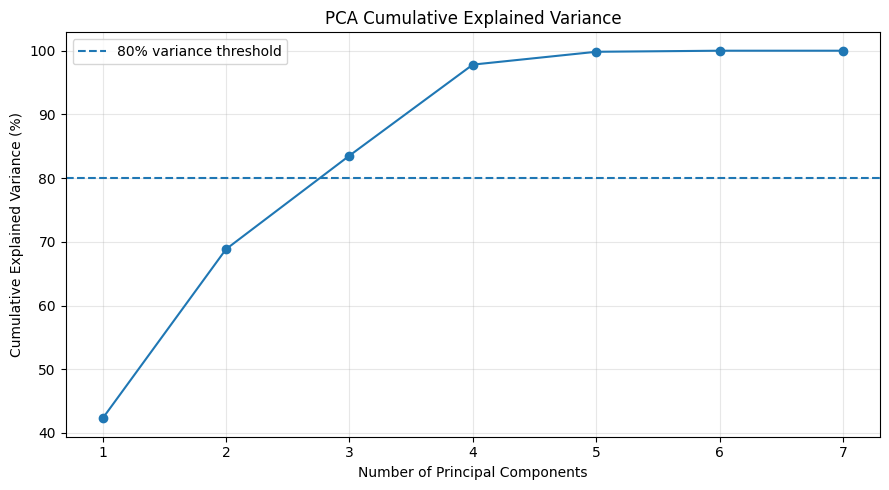

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(
    y=80,
    linestyle="--",
    label="80% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

n_components = n_components_80

pca_reduced = PCA(n_components=n_components)
X_reduced = pca_reduced.fit_transform(X_scaled)

pca_columns = [
    f"PC{i+1}" for i in range(n_components)
]

pca_customer_data = pd.DataFrame(
    X_reduced,
    columns=pca_columns
)

pca_customer_data["churn"] = (
    customer_data["churn"].to_numpy()
)

print("Original number of features:", len(feature_columns))
print("Number of retained components:", n_components)

display(pca_customer_data.head())


Original number of features: 7
Number of retained components: 3


,PC1,PC2,PC3,churn
0,0.055873,-0.677952,-0.165630,0
1,0.078095,-0.944813,0.033524,1
2,-0.224883,0.050368,-0.532876,0
3,0.025131,-0.599993,-0.268234,0
4,0.201545,1.002895,0.631476,0


,PC1,PC2,PC3
transaction_count,0.570,-0.005,-0.185
total_spend,0.577,-0.005,0.115
average_transaction_amount,0.109,-0.001,0.968
total_quantity,0.575,-0.005,-0.117
average_customer_age,0.000,-0.000,0.036
loyalty_years,0.005,0.707,-0.000
num_visits,0.006,0.707,-0.000


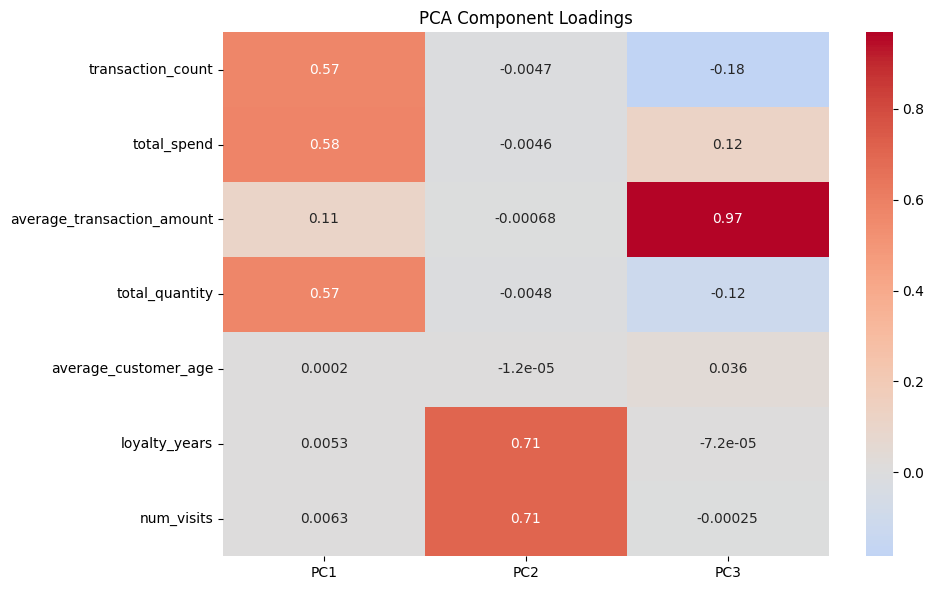

In [8]:

loadings = pd.DataFrame(
    pca_reduced.components_.T,
    index=feature_columns,
    columns=pca_columns
)

display(loadings.round(3))

plt.figure(figsize=(10, 6))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0)
plt.title("PCA Component Loadings")
plt.tight_layout()
plt.show()


In [9]:

X_model = customer_data[feature_columns].copy()
y = customer_data["churn"].astype(int)

print("Churn distribution:")
print(y.value_counts())
print("\nChurn proportions:")
print(y.value_counts(normalize=True).round(3))

if y.nunique() != 2:
    raise ValueError(
        "The churn target must contain both churn classes: 0 and 1."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")


Churn distribution:
churn
0    765026
1    220023
Name: count, dtype: int64

Churn proportions:
churn
0    0.777
1    0.223
Name: proportion, dtype: float64
Training records: 788,039
Testing records: 197,010


In [10]:

model_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.80)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model_pipeline.fit(X_train, y_train)

print("PCA-based logistic regression model trained.")
print(
    "Number of PCA components retained:",
    model_pipeline.named_steps["pca"].n_components_
)


PCA-based logistic regression model trained.
Number of PCA components retained: 3


MODEL EVALUATION
----------------
Accuracy:  0.5349
Precision: 0.2849
Recall:    0.7165
F1-score:  0.4076
ROC-AUC:   0.6557

Detailed classification report:
              precision    recall  f1-score   support

    No churn       0.86      0.48      0.62    153005
       Churn       0.28      0.72      0.41     44005

    accuracy                           0.53    197010
   macro avg       0.57      0.60      0.51    197010
weighted avg       0.73      0.53      0.57    197010



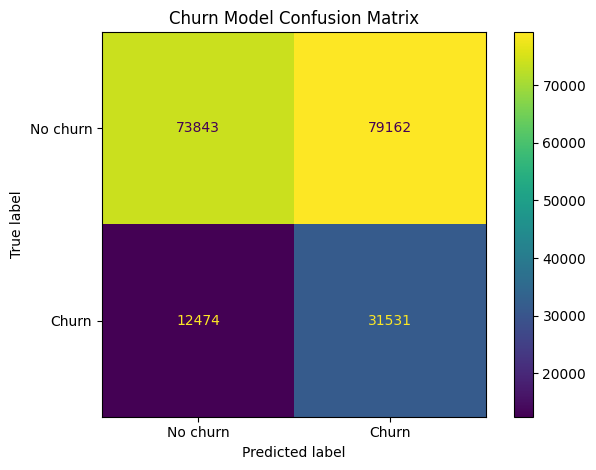

In [11]:

y_pred = model_pipeline.predict(X_test)
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

print("MODEL EVALUATION")
print("----------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_probability):.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No churn", "Churn"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No churn", "Churn"]
)

plt.title("Churn Model Confusion Matrix")
plt.tight_layout()
plt.show()


MODEL EVALUATION
----------------
Accuracy:  0.5349
Precision: 0.2849
Recall:    0.7165
F1-score:  0.4076
ROC-AUC:   0.6557

Detailed classification report:
              precision    recall  f1-score   support

    No churn       0.86      0.48      0.62    153005
       Churn       0.28      0.72      0.41     44005

    accuracy                           0.53    197010
   macro avg       0.57      0.60      0.51    197010
weighted avg       0.73      0.53      0.57    197010



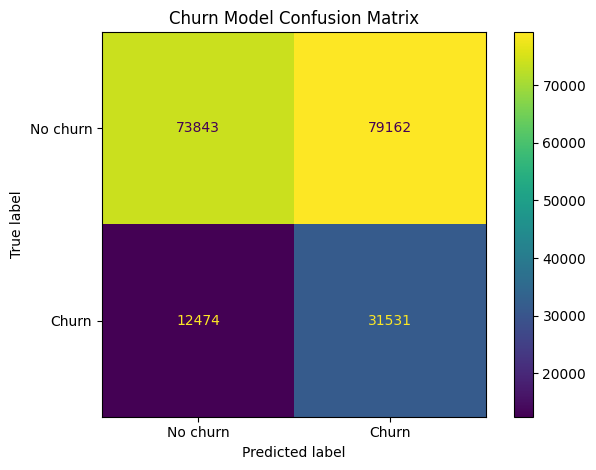

In [12]:

y_pred = model_pipeline.predict(X_test)
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

print("MODEL EVALUATION")
print("----------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_probability):.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No churn", "Churn"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No churn", "Churn"]
)

plt.title("Churn Model Confusion Matrix")
plt.tight_layout()
plt.show()


In [13]:

model_path = "retailmart_pca_churn_model.joblib"

joblib.dump(model_pipeline, model_path)

print("Saved model:", model_path)

# Download the model file from Colab
files.download(model_path)


Saved model: retailmart_pca_churn_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

# Load the saved model
loaded_model = joblib.load("retailmart_pca_churn_model.joblib")

# Use the customer-level feature table
deployment_features = customer_data[feature_columns].copy()

# Predict churn and probability
predicted_churn = loaded_model.predict(deployment_features)
churn_probability = loaded_model.predict_proba(
    deployment_features
)[:, 1]

deployment_results = pd.DataFrame({
    "customer_id": customer_data["customer_id"],
    "actual_churn": customer_data["churn"],
    "predicted_churn": predicted_churn,
    "churn_probability": churn_probability
})

# Sort customers by estimated churn probability
deployment_results = deployment_results.sort_values(
    "churn_probability",
    ascending=False
)

display(deployment_results.head(20))


,customer_id,actual_churn,predicted_churn,churn_probability
765658,c6e47993-fb52-42b7-9244-4430b07a4a88,1,1,0.638559
7481,01f64936-93b2-4479-bc56-28dc0b6623bc,0,1,0.638459
257453,42b5f306-d627-4de4-9c8a-2bfb2e6ea7e5,0,1,0.638105
928404,f13a9c22-7595-4c84-873e-1e79cc18eb0a,1,1,0.638094
339714,5817e882-6c1d-402a-97aa-7aaed3d76390,1,1,0.638058
861497,dfca5903-d71c-4d00-ac19-3ec0550fb47d,1,1,0.638040
681866,b108517d-e407-4e28-a009-f7c3126b435a,1,1,0.637993
392492,65cec39b-b706-44b4-8a8f-765441186fd9,1,1,0.637931
849614,dcb316aa-ef26-45b0-bc21-81d54d183e2e,1,1,0.637834
545035,8d920c64-a072-4cb0-9c66-aad4ac43d823,1,1,0.637831


In [15]:

output_file = "retailmart_churn_predictions.csv"

deployment_results.to_csv(output_file, index=False)

print("Prediction file created:", output_file)
print(
    "Customers flagged as potential churn risks:",
    int((deployment_results["predicted_churn"] == 1).sum())
)

files.download(output_file)


Prediction file created: retailmart_churn_predictions.csv
Customers flagged as potential churn risks: 554123


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>